In [ ]:
from helpers import *
from feature_metadata import FEATURE_GROUPS, FEATURE_INFO, FEATURE_TYPE_GROUPS
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import csv
import os

In [2]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("/Users/majakubik/Documents/CSE/Machine Learning/project1_ml/data/dataset")

In [3]:
def check_shape(x_train, y_train):
    return x_train.shape, y_train.shape

In [4]:
def check_header(x_train, path):

    with open(os.path.join(path, "x_train.csv")) as f:
        reader = csv.reader(f)
        header = next(reader)

    # remove index
    header = header[1:]

    # check header list size against shape od x_trian
    if int(len(header)) == int(x_train.shape[1]): 
        print("Header okay!")
    return header

In [5]:
# takes name as argument, return the data column for that name
def get_column_by_name(name, header, x_train):
    idx = header.index(name)
    column = x_train[:, idx]
    return column, idx

In [6]:
data_path = "/Users/majakubik/Documents/CSE/Machine Learning/project1_ml/data/dataset"
header = check_header(x_train, data_path)

Header okay!


In [7]:
# gives number of NaNs in each column
def check_missing_features(x_train):
    missing_cols = np.isnan(x_train).sum(axis=0)
    return missing_cols

# gives number of NaNs in each row
def check_missing_observations(x_train):
    missing_obs = np.isnan(x_train).sum(axis=1)
    return missing_obs

In [8]:
# x_train = np.delete(x_train, column_index, axis=1)
missing_cols = check_missing_features(x_train)
print(missing_cols)

mask_mis = np.array(missing_cols).sum(axis = 0)
mask_mis = mask_mis > 300000
header_array = np.array(header)

print(header_array[mask_mis])

[     0      0      0      0      0      0      0      0      0 139415
 139415 328103 139416 139415 328103 139433 139524 139525 188720 188720
 188721 188720 327334 188719 189287 192544      2      1      0 159860
      0      0      1      1      1 196334      0  43801  43801      0
      0 284153      1      0      0      1      0      0      5 285915
      0      0      0      0 139415 318245 139415      1      0      3
   2471   3207   3946   4407 279663   6933   7743   8293   8728   9149
   9432   9862  10541 191379 282510 237369  11007  11765 170906 171212
 171522  20738  21567  22468  23149  23759  24502  26205 107829 109141
 109407 109690 181261 181400  28647 226907 227043 227197 229088  29911
  30600 186763 186001  31022  32080 243418 243561 266689 266689 306425
 306426 306428 306429 306429 306629 306429 306430 306430 247299 310302
 310320 310346 310367 310392 310403 310450 265347 325762 325769 325769
 327339 326264 325775 325777 325777 325780 241493 318477 318489 325051
 31850

In [9]:
# gives number of NaNs in each column
missing_rows = check_missing_observations(x_train)
missing_rows_300 = missing_rows <= 150

print(len(missing_rows[missing_rows_300]))

239566


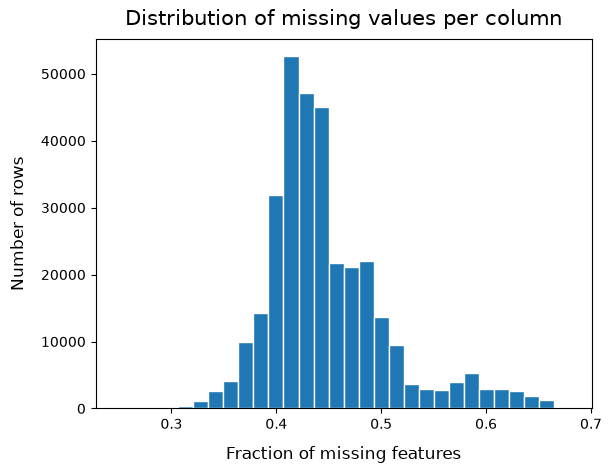

In [10]:
frac_missing_rows = missing_rows / x_train.shape[1]

plt.hist(frac_missing_rows, bins=30, edgecolor="white")
plt.xlabel("Fraction of missing features", fontsize=12, labelpad=10)
plt.ylabel("Number of rows", fontsize=12, labelpad=10)
plt.title("Distribution of missing values per column", fontsize=15, pad=10)
plt.show()

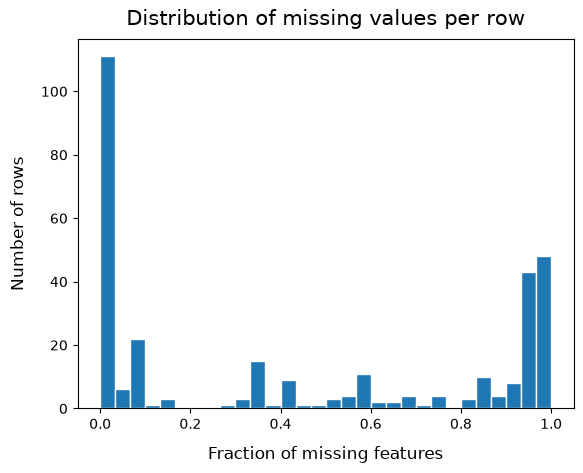

In [11]:
frac_missing_cols = missing_cols / x_train.shape[0]

plt.hist(frac_missing_cols, bins=30, edgecolor="white")
plt.xlabel("Fraction of missing features", fontsize=12, labelpad=10)
plt.ylabel("Number of rows", fontsize=12, labelpad=10)
plt.title("Distribution of missing values per row", fontsize=15, pad=10)
plt.show()

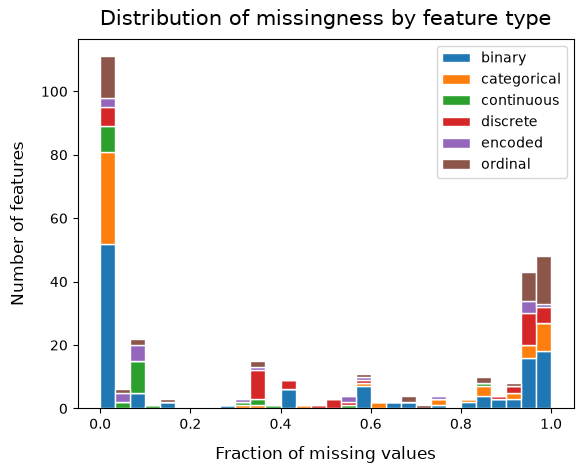

In [71]:
data_types = sorted(set(FEATURE_INFO[f]["data_type"] for f in header_array))

plt.hist(
    [frac_missing_cols[[FEATURE_INFO[f]["data_type"] == t for f in header_array]] for t in data_types],
    bins=30,
    stacked=True,
    label=data_types,
    edgecolor="white"
)

plt.xlabel("Fraction of missing values", fontsize=12, labelpad=10)
plt.ylabel("Number of features", fontsize=12, labelpad=10)
plt.title("Distribution of missingness by feature type", fontsize=15, pad=10)
plt.legend()
plt.show()

In [31]:
high_missing_mask = frac_missing_cols > 0.9

high_miss_features = header_array[high_missing_mask]

print("Features above 90% missingness:", len(high_miss_features))
print(high_miss_features)

Features above 90% missingness: 99
['COLGHOUS' 'LADULT' 'CCLGHOUS' 'NUMPHON2' 'INSULIN' 'BLDSUGAR' 'FEETCHK2'
 'DOCTDIAB' 'CHKHEMO3' 'FEETCHK' 'EYEEXAM' 'DIABEYE' 'DIABEDU' 'CRGVREL1'
 'CRGVLNG1' 'CRGVHRS1' 'CRGVPRB1' 'CRGVPERS' 'CRGVHOUS' 'CRGVMST2'
 'VIDFCLT2' 'VIREDIF3' 'VIPRFVS2' 'VINOCRE2' 'VIEYEXM2' 'VIINSUR2'
 'VICTRCT4' 'VIGLUMA2' 'VIMACDG2' 'CDHOUSE' 'CDASSIST' 'CDHELP' 'CDSOCIAL'
 'CDDISCUS' 'WTCHSALT' 'LONGWTCH' 'DRADVISE' 'ASTHMAGE' 'ASATTACK'
 'ASERVIST' 'ASDRVIST' 'ASRCHKUP' 'ASACTLIM' 'ASYMPTOM' 'ASNOSLEP'
 'ASTHMED3' 'ASINHALR' 'HAREHAB1' 'STREHAB1' 'CVDASPRN' 'ASPUNSAF'
 'RLIVPAIN' 'RDUCHART' 'RDUCSTRK' 'ARTTODAY' 'ARTHWGT' 'ARTHEXER'
 'ARTHEDU' 'TETANUS' 'HPVADVC2' 'HPVADSHT' 'SHINGLE2' 'HADMAM' 'HOWLONG'
 'HADPAP2' 'LASTPAP2' 'HPVTEST' 'HPLSTTST' 'HADHYST2' 'PROFEXAM'
 'LENGEXAM' 'LSTBLDS3' 'HADSGCO1' 'LASTSIG3' 'PCPSAAD2' 'PCPSADI1'
 'PCPSARE1' 'PSATEST1' 'PSATIME' 'PCPSARS1' 'PCPSADE1' 'PCDMDECN'
 'SCNTPAID' 'SCNTWRK1' 'SCNTLPAD' 'SCNTLWK1' 'CASTHNO2' 'EMTSUPRT'
 '

In [35]:
miss_90_categories = [FEATURE_INFO[feature]["category"] for feature in high_miss_features]
miss_90_categries_unique, miss_90_counts = np.unique_counts(miss_90_categories)

for cat, count in zip(miss_90_categries_unique, miss_90_counts):
    print(f"Category: {cat}, {count}")

Category: arthritis_musculoskeletal, 4
Category: cardiovascular_metabolic, 7
Category: caregiving_child, 8
Category: cognitive_health, 5
Category: demographics_socioeconomic, 1
Category: diabetes_management, 9
Category: diet_nutrition, 3
Category: mental_health, 10
Category: preventive_health_screening, 24
Category: respiratory, 10
Category: social_context, 6
Category: survey_administration, 3
Category: vision, 9


In [17]:
keep_mask = frac_missing_cols <= 0.9

x_train_reduced = x_train[:, keep_mask]
x_test_reduced = x_test[:, keep_mask]
features_reduced = header_array[keep_mask]

print("Original features:", x_train.shape[1])
print("Remaining features:", x_train_reduced.shape[1])
print("Removed features:", (~keep_mask).sum())

Original features: 321
Remaining features: 222
Removed features: 99


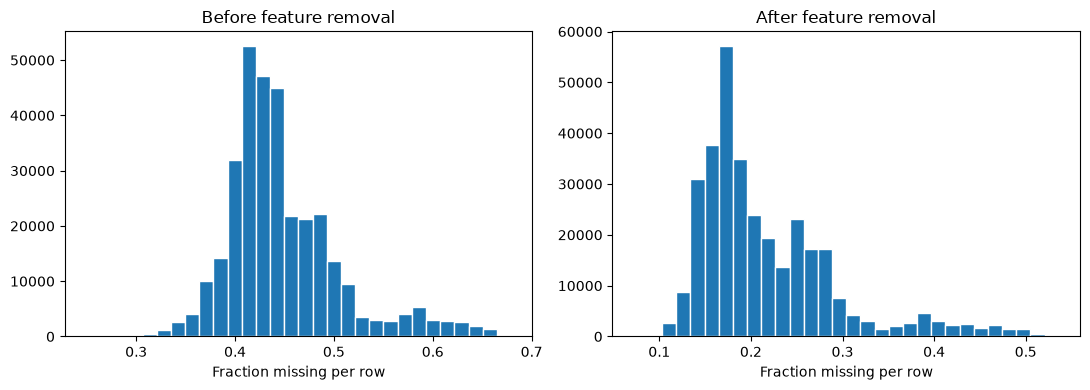

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(np.isnan(x_train).mean(axis=1), bins=30, edgecolor="white")
axes[0].set_title("Before feature removal")
axes[0].set_xlabel("Fraction missing per row")

axes[1].hist(np.isnan(x_train_reduced).mean(axis=1), bins=30, edgecolor="white")
axes[1].set_title("After feature removal")
axes[1].set_xlabel("Fraction missing per row")

plt.tight_layout()
plt.show()

In [20]:
for i, feature in enumerate(header_array):
    values = x_train[:, i]
    unique = np.unique(values[~np.isnan(values)])

    print(f"{feature:12} | Unique: {len(unique):5} | Range: {unique.min() if len(unique) else None} – {unique.max() if len(unique) else None}")

_STATE       | Unique:    53 | Range: 1.0 – 72.0
FMONTH       | Unique:    12 | Range: 1.0 – 12.0
IDATE        | Unique:   414 | Range: 1012016.0 – 12312015.0
IMONTH       | Unique:    12 | Range: 1.0 – 12.0
IDAY         | Unique:    31 | Range: 1.0 – 31.0
IYEAR        | Unique:     2 | Range: 2015.0 – 2016.0
DISPCODE     | Unique:     2 | Range: 1100.0 – 1200.0
SEQNO        | Unique: 21780 | Range: 2015000001.0 – 2015023235.0
_PSU         | Unique: 21780 | Range: 2015000001.0 – 2015023235.0
CTELENUM     | Unique:     1 | Range: 1.0 – 1.0
PVTRESD1     | Unique:     2 | Range: 1.0 – 2.0
COLGHOUS     | Unique:     1 | Range: 1.0 – 1.0
STATERES     | Unique:     1 | Range: 1.0 – 1.0
CELLFON3     | Unique:     2 | Range: 1.0 – 2.0
LADULT       | Unique:     2 | Range: 1.0 – 2.0
NUMADULT     | Unique:    16 | Range: 1.0 – 20.0
NUMMEN       | Unique:    12 | Range: 0.0 – 18.0
NUMWOMEN     | Unique:    11 | Range: 0.0 – 10.0
CTELNUM1     | Unique:     1 | Range: 1.0 – 1.0
CELLFON2     | Uniqu

In [21]:
print("Data type:", x_train.dtype)
print("All numerical:", np.issubdtype(x_train.dtype, np.number))

Data type: float64
All numerical: True


In [ ]:
feature_names = np.array(header[:])  # Exclude ID column
feature_to_idx = {feature: i for i, feature in enumerate(feature_names)}

features = ["_AGE80", "_BMI5", "HTM4", "WTKG3"]

for feature in features:
    x = x_train[:, feature_to_idx[feature]]
    valid = np.isfinite(x) & np.isin(y_train, [-1, 1])

    corr = np.corrcoef(x[valid], y_train[valid])[0, 1]
    print(f"{feature:12}: {corr:.4f}")

_AGE80      : 0.2245
_BMI5       : 0.0543
HTM4        : 0.0118
WTKG3       : 0.0533


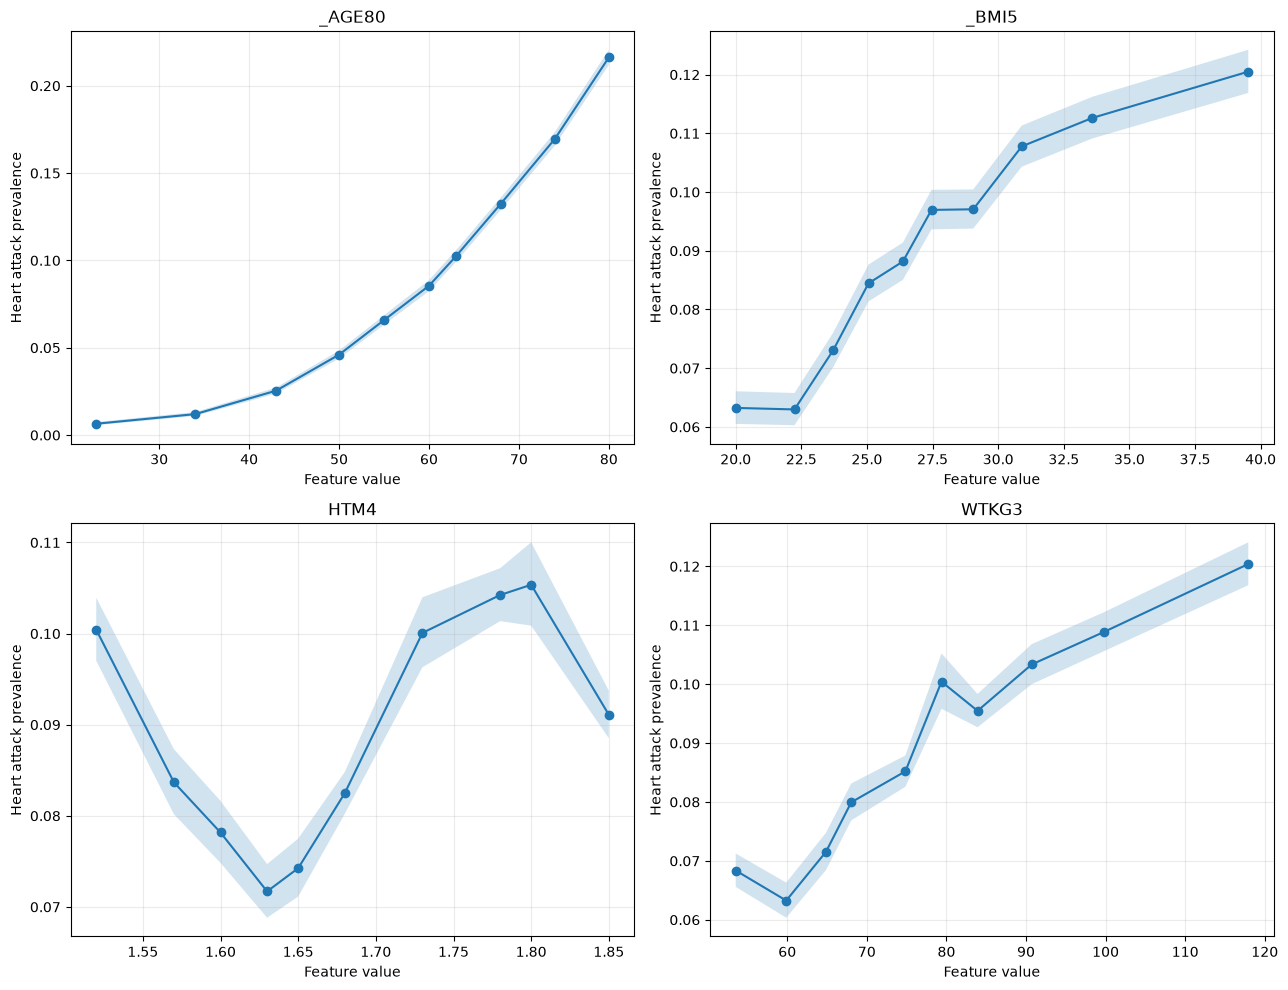

In [ ]:
features = ["_AGE80", "_BMI5", "HTM4", "WTKG3"]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, feature in zip(axes.flat, features):
    x = x_train[:, feature_to_idx[feature]]
    y = y_train.ravel()

    valid = np.isfinite(x) & np.isin(y, [-1, 1])
    x, y = x[valid], (y[valid] == 1).astype(float)

    # Quantile bins
    bins = np.unique(np.quantile(x, np.linspace(0, 1, 11)))
    bin_idx = np.digitize(x, bins[1:-1])

    n_bins = len(bins) - 1
    counts = np.bincount(bin_idx, minlength=n_bins)
    positives = np.bincount(bin_idx, weights=y, minlength=n_bins)

    prevalence = positives / counts
    centers = np.array([
    np.median(x[bin_idx == i])
    for i in range(n_bins)
])

    # Wilson 95% confidence intervals
    z = 1.96
    denominator = 1 + z**2 / counts
    center_ci = (prevalence + z**2 / (2 * counts)) / denominator
    margin = z * np.sqrt(prevalence * (1 - prevalence) / counts + z**2 / (4 * counts**2)) / denominator

    lower = center_ci - margin
    upper = center_ci + margin

    ax.plot(centers, prevalence, marker="o", label="Prevalence")
    ax.fill_between(centers, lower, upper, alpha=0.2, label="95% CI")

    ax.set_title(feature)
    ax.set_xlabel("Feature value")
    # target is heart attack or coronary heart disease
    ax.set_ylabel("MICHD prevalence")
    ax.grid(alpha=0.25)


plt.tight_layout()
plt.show()

In [77]:
idx = {f: i for i, f in enumerate(header_array)}
valid_tuples = []

for f in FEATURE_TYPE_GROUPS["binary"]:
    x = x_train[:, idx[f]]
    codes = [v for c in FEATURE_INFO[f]["nonresponse_codes"].values() for v in c]
    valid_tuples.append(tuple(np.unique(x[~np.isnan(x) & ~np.isin(x, codes)])))

for values, count in Counter(valid_tuples).most_common():
    print(f"{str(tuple(int(v) for v in values))}, {count} features")

(1, 2), 111 features
(1,), 6 features
(0, 1), 5 features
(1100, 1200), 1 features
(2015, 2016), 1 features


In [52]:
nan_rates, missing_rates = [], []

for f in FEATURE_TYPE_GROUPS["binary"]:
    x = x_train[:, idx[f]]
    codes = [v for c in FEATURE_INFO[f]["nonresponse_codes"].values() for v in c]

    nan_rates.append(np.isnan(x).mean())
    missing_rates.append((np.isnan(x) | np.isin(x, codes)).mean())

print(f"Average missing (NaN only): {np.mean(nan_rates):.2%}")
print(f"Average missing (including special codes): {np.mean(missing_rates):.2%}")

Average missing (NaN only): 44.07%
Average missing (including special codes): 46.32%


Average missing (NaN): 39.90%
Average missing (including special codes): 40.70%


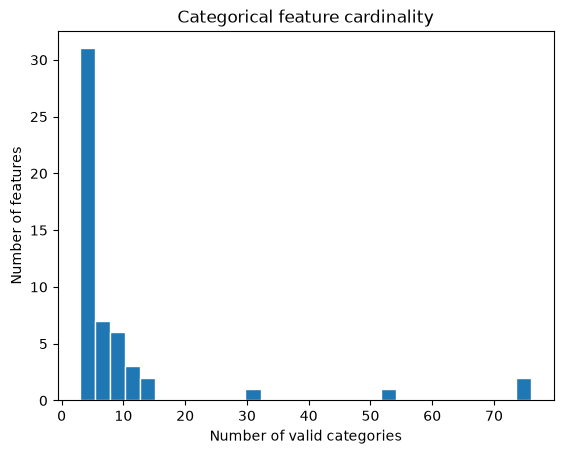

In [81]:
n_categories, nan_rates, missing_rates = [], [], []

for f in FEATURE_TYPE_GROUPS["categorical"]:
    x = x_train[:, idx[f]]
    codes = [v for c in FEATURE_INFO[f]["nonresponse_codes"].values() for v in c]
    valid = np.unique(x[~np.isnan(x) & ~np.isin(x, codes)])

    n_categories.append(len(valid))
    nan_rates.append(np.isnan(x).mean())
    missing_rates.append((np.isnan(x) | np.isin(x, codes)).mean())

print(f"Average missing (NaN): {np.mean(nan_rates):.2%}")
print(f"Average missing (including special codes): {np.mean(missing_rates):.2%}")

plt.hist([n for n in n_categories if n <= 100], bins=30, edgecolor="white")
plt.xlabel("Number of valid categories")
plt.ylabel("Number of features")
plt.title("Categorical feature cardinality")
plt.show()

In [ ]:
excluded_features = [
    "SEQNO", "_PSU", "_STSTR", "_STRWT",
    "_RAWRAKE", "_WT2RAKE", "_CLLCPWT", "_LLCPWT", "_DUALCOR",
    "CTELENUM", "CTELNUM1", "CELLFON2", "STATERES",
    "COLGHOUS", "CCLGHOUS", "LADULT", "DISPCODE", "QSTVER",
    "FMONTH", "IDATE", "IDAY", "IYEAR", "FLSHTMY2", "HIVTSTD3"
]

In [55]:
n_levels, nan_rates, missing_rates = [], [], []

for f in FEATURE_TYPE_GROUPS["ordinal"]:
    x = x_train[:, idx[f]]
    codes = [v for c in FEATURE_INFO[f]["nonresponse_codes"].values() for v in c]
    valid = np.unique(x[~np.isnan(x) & ~np.isin(x, codes)])

    n_levels.append(len(valid))
    nan_rates.append(np.isnan(x).mean())
    missing_rates.append((np.isnan(x) | np.isin(x, codes)).mean())

print("Number of levels:", sorted(set(n_levels)))
print(f"Average missing (NaN): {np.mean(nan_rates):.2%}")
print(f"Average missing (including nonresponses): {np.mean(missing_rates):.2%}")

Number of levels: [3, 4, 5, 6, 7, 8, 11, 13]
Average missing (NaN): 59.42%
Average missing (including nonresponses): 61.12%
